In [ ]:
A2

In [1]:

import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from scipy.stats import loguniform

# Load dataset
X, y = load_breast_cancer(return_X_y=True)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 1. Perceptron hyperparameter tuning
perceptron_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Perceptron())
])

perceptron_params = {
    "model__alpha": loguniform(1e-5, 1e-1),
    "model__max_iter": [500, 1000, 2000],
    "model__penalty": [None, "l2", "l1", "elasticnet"],
    "model__eta0": [0.01, 0.1, 1.0]
}

perceptron_search = RandomizedSearchCV(
    estimator=perceptron_pipeline,
    param_distributions=perceptron_params,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

perceptron_search.fit(X_train, y_train)

print("PERCEPTRON")
print("Best Parameters:", perceptron_search.best_params_)
print("Best CV Accuracy:", perceptron_search.best_score_)
print("Test Accuracy:", perceptron_search.score(X_test, y_test))


# 2. MLP hyperparameter tuning
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        early_stopping=True,
        random_state=42
    ))
])

mlp_params = {
    "model__hidden_layer_sizes": [
        (50,), (100,), (50, 50), (100, 50)
    ],
    "model__activation": ["relu", "tanh"],
    "model__solver": ["adam", "sgd"],
    "model__alpha": loguniform(1e-5, 1e-1),
    "model__learning_rate_init": loguniform(1e-4, 1e-1),
    "model__max_iter": [500, 1000]
}

mlp_search = RandomizedSearchCV(
    estimator=mlp_pipeline,
    param_distributions=mlp_params,
    n_iter=10,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

mlp_search.fit(X_train, y_train)

print("\nMLP")
print("Best Parameters:", mlp_search.best_params_)
print("Best CV Accuracy:", mlp_search.best_score_)
print("Test Accuracy:", mlp_search.score(X_test, y_test))


PERCEPTRON
Best Parameters: {'model__alpha': np.float64(4.207053950287933e-05), 'model__eta0': 1.0, 'model__max_iter': 2000, 'model__penalty': 'elasticnet'}
Best CV Accuracy: 0.9736263736263737
Test Accuracy: 0.9473684210526315

MLP
Best Parameters: {'model__activation': 'relu', 'model__alpha': np.float64(0.015352246941973482), 'model__hidden_layer_sizes': (50, 50), 'model__learning_rate_init': np.float64(0.015702970884055395), 'model__max_iter': 500, 'model__solver': 'adam'}
Best CV Accuracy: 0.9692307692307693
Test Accuracy: 0.9473684210526315


A3

In [2]:
pip install scikit-learn pandas xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00


In [3]:

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define classifiers
models = {
    "Perceptron": make_pipeline(
        StandardScaler(), Perceptron(random_state=42)
    ),
    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(max_iter=2000, random_state=42)
    ),
    "SVM": make_pipeline(
        StandardScaler(), SVC(probability=True, random_state=42)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "CatBoost": CatBoostClassifier(
        iterations=100, verbose=0, random_seed=42,
        allow_writing_files=False
    ),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=100, eval_metric="logloss",
        random_state=42, n_jobs=-1
    ),
    "Naive Bayes": make_pipeline(
        StandardScaler(), GaussianNB()
    )
}

# Evaluate models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # Obtain scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

# Display comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
)

print("\nCLASSIFIER PERFORMANCE COMPARISON")
print(results_df.round(4).to_string(index=False))

# Save results as CSV
results_df.to_csv("classifier_comparison.csv", index=False)
print("\nResults saved to classifier_comparison.csv")



CLASSIFIER PERFORMANCE COMPARISON
   Classifier  Accuracy  Precision  Recall  F1-Score  ROC-AUC
          SVM    0.9825     0.9861  0.9861    0.9861   0.9950
          MLP    0.9649     0.9857  0.9583    0.9718   0.9940
   Perceptron    0.9561     0.9855  0.9444    0.9645   0.9940
Random Forest    0.9561     0.9589  0.9722    0.9655   0.9937
     CatBoost    0.9561     0.9467  0.9861    0.9660   0.9947
      XGBoost    0.9561     0.9467  0.9861    0.9660   0.9927
     AdaBoost    0.9561     0.9467  0.9861    0.9660   0.9825
  Naive Bayes    0.9298     0.9444  0.9444    0.9444   0.9868
Decision Tree    0.9123     0.9559  0.9028    0.9286   0.9157

Results saved to classifier_comparison.csv


A4

In [4]:

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load dataset
X, y = load_breast_cancer(return_X_y=True)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create pipelines
pipelines = {
    "Perceptron": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", Perceptron(random_state=42))
    ]),

    "MLP": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=2000,
            random_state=42
        ))
    ])
}

# Train, predict and evaluate
results = []

for name, pipeline in pipelines.items():
    # Train the entire pipeline
    pipeline.fit(X_train, y_train)

    # Make predictions
    y_pred = pipeline.predict(X_test)

    # Perform 5-fold cross-validation on training data
    cv_scores = cross_val_score(
        pipeline, X_train, y_train, cv=5, scoring="accuracy"
    )

    results.append({
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "CV Mean Accuracy": cv_scores.mean()
    })

    print("\nModel:", name)
    print(classification_report(y_test, y_pred))

# Display comparison
results_df = pd.DataFrame(results)
print("\nPipeline Results:")
print(results_df.round(4).to_string(index=False))



Model: Perceptron
              precision    recall  f1-score   support

           0       0.91      0.98      0.94        42
           1       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114


Model: MLP
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        42
           1       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114


Pipeline Results:
     Model  Test Accuracy  CV Mean Accuracy
Perceptron         0.9561            0.9407
       MLP         0.9649            0.9780


A5

In [5]:
pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=8c2a9d51955a8e65ace0fe817cbf02f4d16a2f562089acd8920d77f974d7a9a5
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime



Model: Perceptron
Predicted class: malignant
Feature contributions:
worst texture > 29.37: -0.2738
area error > 44.77: -0.2406
radius error > 0.47: -0.1909
worst concavity > 0.39: -0.1878
mean compactness > 0.13: 0.1758
concave points error > 0.01: -0.1678
worst area > 1033.50: -0.1582
fractal dimension error > 0.00: 0.1477
worst concave points > 0.16: -0.1435
worst radius > 18.55: -0.1323


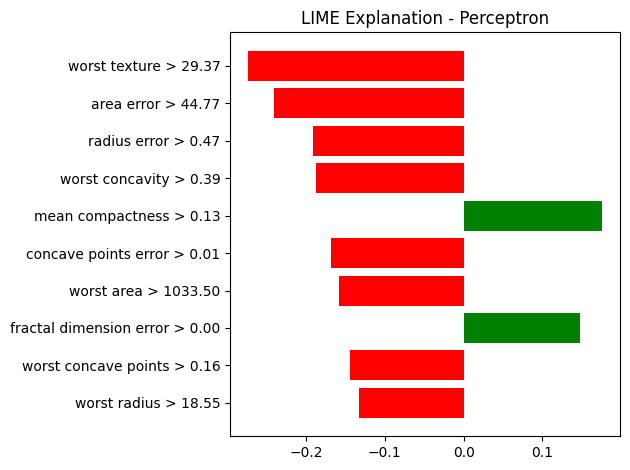


Model: MLP
Predicted class: malignant
Predicted probabilities: [[1. 0.]]
Feature contributions:
area error > 44.77: -0.2407
worst area > 1033.50: -0.2361
radius error > 0.47: -0.2210
worst radius > 18.55: -0.2127
compactness error > 0.03: 0.1952
worst perimeter > 124.95: -0.1943
worst texture > 29.37: -0.1900
worst concave points > 0.16: -0.1749
fractal dimension error > 0.00: 0.1638
worst concavity > 0.39: -0.1607


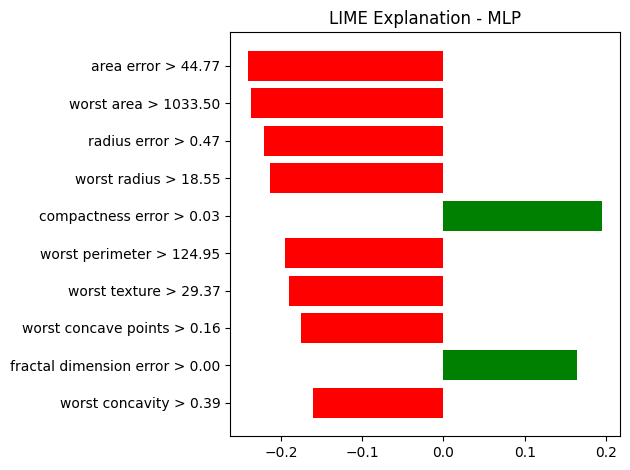

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from lime.lime_tabular import LimeTabularExplainer
from scipy.special import softmax
from sklearn.datasets import load_breast_cancer

# Feature and class names
dataset = load_breast_cancer()
feature_names = dataset.feature_names.tolist()
class_names = dataset.target_names.tolist()

# Create LIME explainer
explainer = LimeTabularExplainer(
    training_data=np.asarray(X_train),
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    random_state=42
)

# Explain one test instance
instance_index = 0
instance = np.asarray(X_test)[instance_index]

for name, pipeline in pipelines.items():

    # Custom prediction function for LIME
    def lime_predict(data, model=pipeline):
        if hasattr(model, "predict_proba"):
            return model.predict_proba(data)

        # Perceptron: convert decision scores to probability-like scores
        scores = model.decision_function(data)

        if scores.ndim == 1:
            scores = np.column_stack([-scores, scores])

        return softmax(scores, axis=1)

    prediction = pipeline.predict(instance.reshape(1, -1))[0]

    print("\nModel:", name)
    print("Predicted class:", class_names[prediction])

    if hasattr(pipeline, "predict_proba"):
        print(
            "Predicted probabilities:",
            pipeline.predict_proba(instance.reshape(1, -1)).round(4)
        )

    # Generate LIME explanation
    explanation = explainer.explain_instance(
        data_row=instance,
        predict_fn=lime_predict,
        num_features=10,
        num_samples=5000
    )

    print("Feature contributions:")
    for feature, contribution in explanation.as_list():
        print(f"{feature}: {contribution:.4f}")

    # Plot explanation
    fig = explanation.as_pyplot_figure()
    plt.title(f"LIME Explanation - {name}")
    plt.tight_layout()
    plt.show()

    # Save explanation
    explanation.save_to_file(
        name.lower() + "_lime_explanation.html"
    )
